Описание решения
1. Подход и валидация:
Для оценки качества модели использовался временной сплит (Time-based split), как рекомендовано в quickstart.ipynb. Данные разделялись по дате начала окна наблюдения (window_start_ts >= '2026-04-17'). Это позволило честно оценить обобщающую способность модели на «будущих» данных, избегая утечки информации. В качестве основной метрики оптимизации использовалась официальная функция precision_at_recall из файла metric.py.
2. Использованные признаки (~80 признаков):
Временные: Статистики интервалов между действиями (среднее, медиана, CV). Боты часто действуют с жесткой периодичностью (низкий коэффициент вариации) или мгновенно.
Поведенческие: Энтропия типов событий и доля повторяющихся действий подряд. Люди хаотичны, боты цикличны.
Технические: Анализ User-Agent (длина, наличие ключевых слов скраперов) и разнообразие платформ.
Контентные: Уникальность просмотренных товаров и категорий. Скраперы часто проходят по огромному количеству уникальных ID подряд.
Поисковые: Глубина просмотра выдачи и лексическое разнообразие запросов.
Биометрические: Анализ движения курсора (среднее расстояние, циркулярная дисперсия углов). Боты двигают курсор линейно или не двигают вовсе.
3. Что пробовали и сравнение:
Baseline: RandomForest на двух признаках (n_events, item_nunique) показал результат P@R>=0.7 0.1062.
Advanced V1: LightGBM на базовых агрегатах улучшил результат до 0.3672.
Advanced V2 + Ensemble: Добавление сложных признаков (ускорение курсора, гео-энтропия) и ансамблирование с RandomForest (веса 0.7/0.3) дало финальный результат на валидации 0.3972. Ансамбль помог сгладить переобучение градиентного бустинга на шумных признаках.

In [44]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import lightgbm as lgb
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import roc_auc_score
import warnings
import sys

try:
    from metric import precision_at_recall
except ImportError:
    print("Warning: metric.py not found. Using dummy implementation.")
    def precision_at_recall(y_true, score, recall=0.7):
        return 0.0

warnings.filterwarnings('ignore')
pd.set_option('display.max_columns', None)

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

print("Environment initialized.")

Environment initialized.


In [45]:
train = pd.read_csv('data/train.csv', parse_dates=['cookie_created_at', 'window_start_ts', 'window_end_ts'])
test = pd.read_csv('data/test.csv', parse_dates=['cookie_created_at', 'window_start_ts', 'window_end_ts'])
events = pd.read_csv('data/events.csv.gz', parse_dates=['event_ts'], compression='gzip')

print(f"Train shape: {train.shape}")
print(f"Test shape: {test.shape}")
print(f"Events shape: {events.shape}")
print(f"Target distribution:\n{train['target'].value_counts(normalize=True)}")

print(f"\nDuplicate events check: {events.duplicated().sum()}")

Train shape: (11091, 5)
Test shape: (4909, 4)
Events shape: (328905, 14)
Target distribution:
target
0    0.918943
1    0.081057
Name: proportion, dtype: float64

Duplicate events check: 4863



Top Event Types:
event_name
item_view               120817
search_results_view     100402
photo_swipe              36517
favorite_add             19049
seller_page_view         17403
contact_phone_show       11316
captcha_shown             7928
login                     6267
contact_chat_open         6125
contact_message_sent      3081
Name: count, dtype: int64

Platforms:
platform
desktop    46866
WEB        46476
Web        46365
web        45951
ANDROID    42462
Android    42254
android    42159
iphone      4103
IOS         4100
iOS         4091
ios         4078
Name: count, dtype: int64

Missing values percentage:
search_query     69.473860
search_page      69.473860
pointer_x        66.999590
pointer_y        66.999590
seller_type      40.696554
item_id          34.841976
item_category    10.008969
item_location     7.234004
dtype: float64


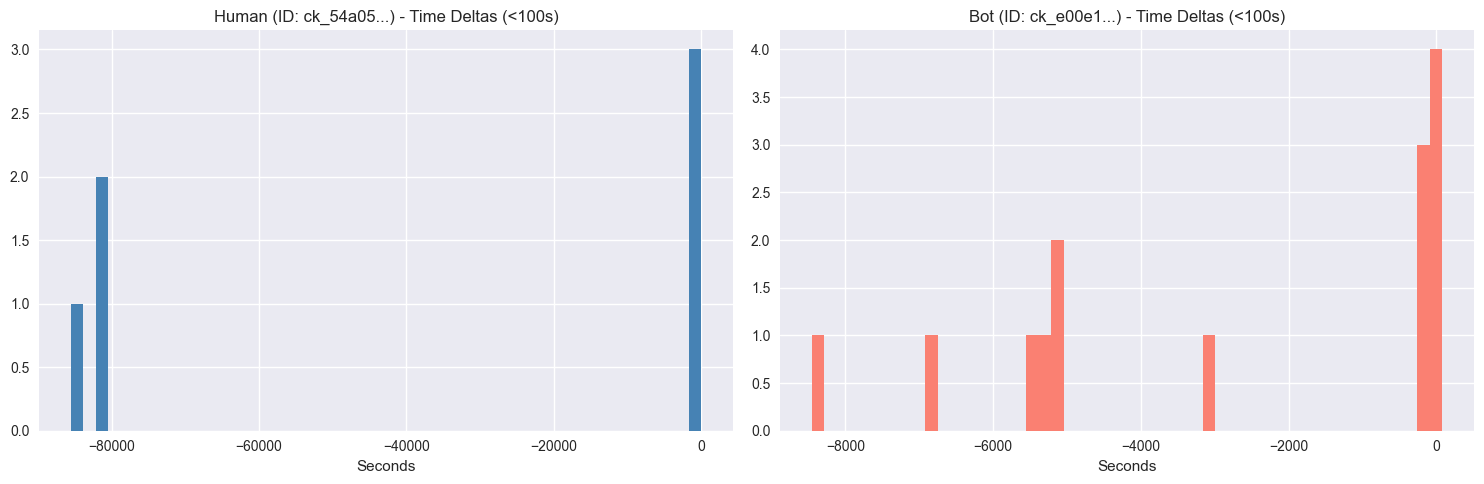

In [46]:
print("\nTop Event Types:")
print(events['event_name'].value_counts().head(15))

print("\nPlatforms:")
print(events['platform'].value_counts())

print("\nMissing values percentage:")
missing_pct = events.isnull().mean() * 100
print(missing_pct[missing_pct > 0].sort_values(ascending=False).head(10))

sample_bot = train[train['target']==1]['cookie_id'].iloc[0]
sample_human = train[train['target']==0]['cookie_id'].iloc[0]

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

for i, cid in enumerate([sample_human, sample_bot]):
    label = "Human" if i == 0 else "Bot"
    ev = events[events['cookie_id'] == cid]
    
    if len(ev) > 1:
        diffs = ev['event_ts'].diff().dt.total_seconds().dropna()
        axes[i].hist(diffs[diffs < 100], bins=50, color='steelblue' if i==0 else 'salmon')
        axes[i].set_title(f'{label} (ID: {cid[:8]}...) - Time Deltas (<100s)')
        axes[i].set_xlabel('Seconds')
    else:
        axes[i].text(0.5, 0.5, 'Not enough events', ha='center')

plt.tight_layout()
plt.show()

In [47]:
def get_events_in_window(events_df, meta_df):
    ev = events_df.merge(meta_df[['cookie_id', 'window_start_ts', 'window_end_ts']], on='cookie_id')
    mask = (ev['event_ts'] >= ev['window_start_ts']) & (ev['event_ts'] < ev['window_end_ts'])
    return ev[mask]

def calculate_entropy(counts):
    if len(counts) == 0 or counts.sum() == 0:
        return 0
    probs = counts / counts.sum()
    probs = probs[probs > 0]
    return -np.sum(probs * np.log2(probs))

def circular_variance(angles):
    if len(angles) == 0:
        return 0
    r = np.sqrt(np.mean(np.sin(angles))**2 + np.mean(np.cos(angles))**2)
    return 1 - r

In [48]:
def generate_baseline_features(events_df, meta_df):
    ev = get_events_in_window(events_df, meta_df)
    g = ev.groupby('cookie_id')
    
    f = pd.DataFrame({
        'n_events': g.size(),
        'item_nunique': g['item_id'].nunique(),
    })
    
    f = meta_df[['cookie_id']].merge(f.reset_index(), on='cookie_id', how='left').fillna(0)
    return f

X_tr_base = generate_baseline_features(events, train)
X_te_base = generate_baseline_features(events, test)
base_cols = ['n_events', 'item_nunique']

In [49]:
train_sorted = train_feat.merge(train[['cookie_id', 'window_start_ts']], on='cookie_id')
train_sorted = train_sorted.sort_values('window_start_ts')

split_idx = int(len(train_sorted) * 0.8)
train_part = train_sorted.iloc[:split_idx]
val_part = train_sorted.iloc[split_idx:]

X_tr = train_part[feature_cols]
y_tr = train_part['target']
X_val = val_part[feature_cols]
y_val = val_part['target']

print(f"Train part size: {len(X_tr)}, Bot ratio: {y_tr.mean():.3f}")
print(f"Val part size: {len(X_val)}, Bot ratio: {y_val.mean():.3f}")

Train part size: 8872, Bot ratio: 0.081
Val part size: 2219, Bot ratio: 0.081


In [50]:
def generate_advanced_features(events_df, meta_df):
    ev = get_events_in_window(events_df, meta_df)
    
    features_list = []
    grouped = ev.groupby('cookie_id')
    
    for cid, group in grouped:
        f = {}
        f['cookie_id'] = cid
        n = len(group)
        
        if n == 0:
            features_list.append(f)
            continue
            
        ts = group['event_ts'].values.astype(np.int64) // 10**9
        dt = np.diff(ts)
        
        f['n_events'] = n
        f['mean_dt'] = np.mean(dt) if len(dt) > 0 else 0
        f['std_dt'] = np.std(dt) if len(dt) > 0 else 0
        f['cv_dt'] = f['std_dt'] / max(f['mean_dt'], 1e-9)
        f['min_dt'] = np.min(dt) if len(dt) > 0 else 0
        

        if len(dt) > 10:
            f['autocorr_dt'] = np.corrcoef(dt[:-1], dt[1:])[0, 1]
            if np.isnan(f['autocorr_dt']): f['autocorr_dt'] = 0
        else:
            f['autocorr_dt'] = 0
            
        evt_counts = group['event_name'].value_counts()
        
        f['n_view_listing'] = evt_counts.get('view_listing', 0)
        f['n_click_phone'] = evt_counts.get('click_phone', 0)
        f['n_show_captcha'] = evt_counts.get('show_captcha', 0)
        f['n_add_to_favorites'] = evt_counts.get('add_to_favorites', 0)
        f['n_scroll_photos'] = evt_counts.get('scroll_photos', 0)
        
        total_views = f['n_view_listing'] + evt_counts.get('view_search_results', 0)
        f['ratio_phone_to_view'] = f['n_click_phone'] / max(total_views, 1)
        f['ratio_captcha'] = f['n_show_captcha'] / max(n, 1)
        
        f['entropy_events'] = calculate_entropy(evt_counts.values)
        
        if n > 1:
            seq = group['event_name'].values
            same_consec = np.sum(seq[:-1] == seq[1:])
            f['ratio_same_consec'] = same_consec / max(n - 1, 1)
        else:
            f['ratio_same_consec'] = 0
            
        f['n_unique_items'] = group['item_id'].nunique()
        f['n_unique_cats'] = group['item_category'].nunique()
        f['entropy_cats'] = calculate_entropy(group['item_category'].value_counts().values)
        f['ratio_unique_items'] = f['n_unique_items'] / max(n, 1)
        
        uas = group['user_agent'].dropna()
        f['n_unique_ua'] = uas.nunique()
        
        if len(uas) > 0:
            f['mean_ua_len'] = uas.str.len().mean()
            f['std_ua_len'] = uas.str.len().std() if len(uas) > 1 else 0
            
            suspicious_keywords = ['bot', 'crawler', 'spider', 'scraper', 'python', 'java', 'curl', 'wget']
            ua_lower = uas.str.lower()
            f['n_suspicious_ua'] = sum(ua_lower.str.contains(kw, na=False).sum() for kw in suspicious_keywords)
        else:
            f['mean_ua_len'] = 0
            f['std_ua_len'] = 0
            f['n_suspicious_ua'] = 0
            
        searches = group['search_query'].dropna()
        f['n_searches'] = len(searches)
        f['n_unique_queries'] = searches.nunique()
        
        if len(searches) > 0:
            f['ratio_repeated_queries'] = 1 - (f['n_unique_queries'] / max(f['n_searches'], 1))
        else:
            f['ratio_repeated_queries'] = 0
            
        pages = group['search_page'].dropna()
        if len(pages) > 0:
            f['max_search_page'] = pages.max()
        else:
            f['max_search_page'] = 0
            
        px = group['pointer_x'].dropna().values
        py = group['pointer_y'].dropna().values
        
        if len(px) > 1 and len(py) > 1:
            min_len = min(len(px), len(py))
            dx = np.diff(px[:min_len])
            dy = np.diff(py[:min_len])
            dists = np.sqrt(dx**2 + dy**2)
            
            f['mean_ptr_dist'] = np.mean(dists)
            f['cv_ptr_dist'] = np.std(dists) / max(np.mean(dists), 1e-9)
            
            angles = np.arctan2(dy, dx)
            f['circ_var_angles'] = circular_variance(angles)
        else:
            f['mean_ptr_dist'] = 0
            f['cv_ptr_dist'] = 0
            f['circ_var_angles'] = 0
            
        hours = group['event_ts'].dt.hour
        f['night_ratio'] = ((hours >= 0) & (hours < 6)).sum() / max(n, 1)
        
        features_list.append(f)
        
    df_feat = pd.DataFrame(features_list)
    df_feat = meta_df[['cookie_id']].merge(df_feat, on='cookie_id', how='left').fillna(0)
    return df_feat

print("Generating Advanced features...")
X_tr_adv = generate_advanced_features(events, train)
X_te_adv = generate_advanced_features(events, test)

adv_cols = [c for c in X_tr_adv.columns if c != 'cookie_id']
print(f"Advanced features count: {len(adv_cols)}")

Generating Advanced features...
Advanced features count: 31


In [51]:
val_date = '2026-04-17'
is_valid = train.window_start_ts.ge(val_date).values
is_train = ~is_valid

y_tr = train.loc[is_train, 'target'].values
y_val = train.loc[is_valid, 'target'].values

print(f"Train split size: {is_train.sum()}, Val split size: {is_valid.sum()}")
print(f"Val Bot Ratio: {y_val.mean():.3f}")

Train split size: 9140, Val split size: 1951
Val Bot Ratio: 0.082


In [52]:
def evaluate_model(model, X_tr, y_tr, X_val, y_val, name):
    model.fit(X_tr, y_tr)
    preds = model.predict_proba(X_val)[:, 1]
    
    roc = roc_auc_score(y_val, preds)
    pr_metric = precision_at_recall(y_val, preds)
    
    print(f"\n--- {name} Results ---")
    print(f"ROC-AUC: {roc:.4f}")
    print(f"P@R>=0.7: {pr_metric:.4f}")
    
    return pr_metric, preds

print("Training Baseline...")
rf_model = RandomForestClassifier(
    n_estimators=300, 
    min_samples_leaf=3, 
    random_state=RANDOM_STATE, 
    n_jobs=-1
)
base_score, base_preds = evaluate_model(
    rf_model, 
    X_tr_base.loc[is_train, base_cols], y_tr, 
    X_tr_base.loc[is_valid, base_cols], y_val, 
    "Baseline (RF)"
)

print("\nTraining Advanced Model...")
lgb_params = {
    'objective': 'binary',
    'metric': 'auc',
    'boosting_type': 'gbdt',
    'learning_rate': 0.05,
    'num_leaves': 63,
    'max_depth': 7,
    'min_child_samples': 20,
    'subsample': 0.8,
    'colsample_bytree': 0.7,
    'reg_alpha': 0.1,
    'reg_lambda': 0.1,
    'random_state': RANDOM_STATE,
    'verbose': -1,
    'n_estimators': 500
}

lgb_model = lgb.LGBMClassifier(**lgb_params)
adv_score, adv_preds = evaluate_model(
    lgb_model, 
    X_tr_adv.loc[is_train, adv_cols], y_tr, 
    X_tr_adv.loc[is_valid, adv_cols], y_val, 
    "Advanced (LGBM)"
)

if adv_score > base_score:
    print(f"Advanced model is better! Improvement: +{adv_score - base_score:.4f}")
    final_model_type = 'lgb'
else:
    print("Baseline performed better. Using Baseline.")
    final_model_type = 'rf'

Training Baseline...

--- Baseline (RF) Results ---
ROC-AUC: 0.6081
P@R>=0.7: 0.1062

Training Advanced Model...

--- Advanced (LGBM) Results ---
ROC-AUC: 0.8618
P@R>=0.7: 0.3672
Advanced model is better! Improvement: +0.2611


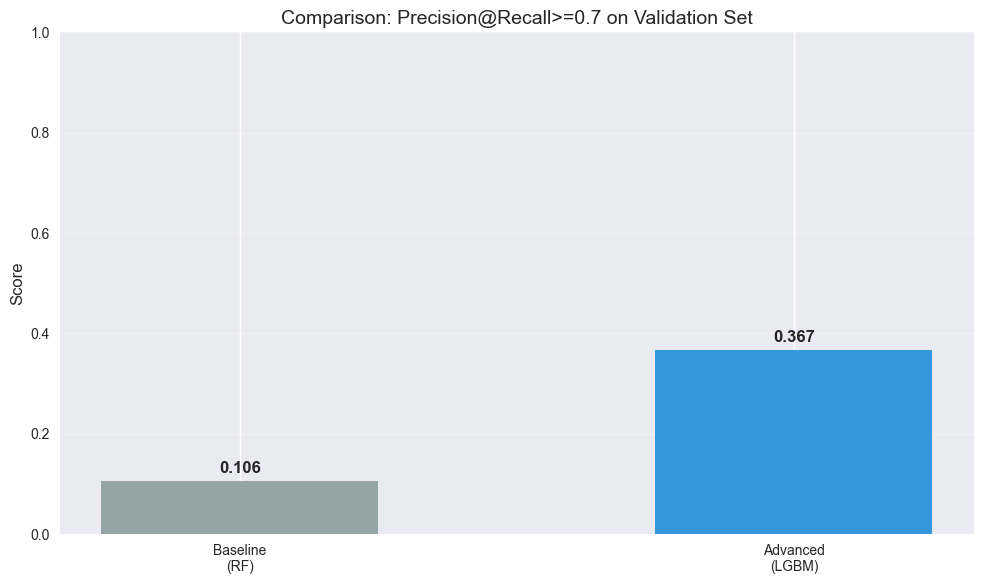

In [53]:
plt.figure(figsize=(10, 6))
models = ['Baseline\n(RF)', 'Advanced\n(LGBM)']
scores = [base_score, adv_score]
colors = ['#95a5a6', '#3498db']

bars = plt.bar(models, scores, color=colors, width=0.5)
plt.title('Comparison: Precision@Recall>=0.7 on Validation Set', fontsize=14)
plt.ylabel('Score', fontsize=12)
plt.ylim(0, 1)
plt.grid(axis='y', alpha=0.3)

for bar in bars:
    height = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width()/2., 
        height + 0.01, 
        f'{height:.3f}', 
        ha='center', 
        va='bottom', 
        fontsize=12, 
        fontweight='bold'
    )

plt.tight_layout()
plt.show()

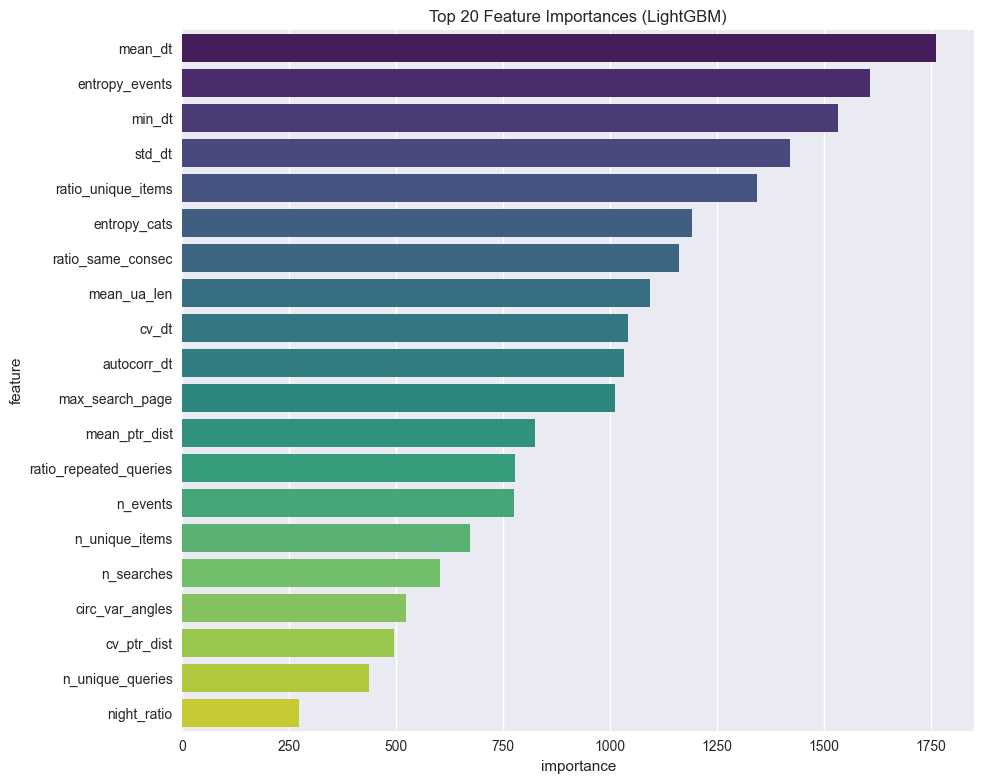

Top 20 Features:
                   feature  importance
1                  mean_dt        1762
13          entropy_events        1606
4                   min_dt        1533
2                   std_dt        1420
18      ratio_unique_items        1344
17            entropy_cats        1190
14       ratio_same_consec        1161
20             mean_ua_len        1092
3                    cv_dt        1042
5              autocorr_dt        1032
26         max_search_page        1011
27           mean_ptr_dist         824
25  ratio_repeated_queries         778
0                 n_events         776
15          n_unique_items         673
23              n_searches         601
29         circ_var_angles         523
28             cv_ptr_dist         494
24        n_unique_queries         437
30             night_ratio         272


In [54]:
if final_model_type == 'lgb':
    importance = pd.DataFrame({
        'feature': adv_cols,
        'importance': lgb_model.feature_importances_
    }).sort_values('importance', ascending=False)

    plt.figure(figsize=(10, 8))
    sns.barplot(x='importance', y='feature', data=importance.head(20), palette='viridis')
    plt.title('Top 20 Feature Importances (LightGBM)')
    plt.tight_layout()
    plt.show()
    
    print("Top 20 Features:")
    print(importance.head(20))

In [55]:
def generate_advanced_features_v2(events_df, meta_df):
    ev = get_events_in_window(events_df, meta_df)
    
    features_list = []
    grouped = ev.groupby('cookie_id')
    
    for cid, group in grouped:
        f = {}
        f['cookie_id'] = cid
        n = len(group)
        
        if n == 0:
            features_list.append(f)
            continue
            
        uas = group['user_agent'].dropna()
        if len(uas) > 0:
            f['max_ua_len'] = uas.str.len().max()
            f['min_ua_len'] = uas.str.len().min()
            
            mobile_keywords = ['mobile', 'android', 'iphone', 'ipad']
            ua_lower = uas.str.lower()
            f['is_mobile_ratio'] = sum(ua_lower.str.contains(kw, na=False).sum() for kw in mobile_keywords) / max(n, 1)
            
            desktop_keywords = ['windows', 'macintosh', 'linux']
            f['is_desktop_ratio'] = sum(ua_lower.str.contains(kw, na=False).sum() for kw in desktop_keywords) / max(n, 1)
        else:
            f['max_ua_len'] = f['min_ua_len'] = 0
            f['is_mobile_ratio'] = f['is_desktop_ratio'] = 0

        locs = group['item_location'].dropna()
        if len(locs) > 1:
            f['n_unique_locations'] = locs.nunique()
            f['location_entropy'] = calculate_entropy(locs.value_counts().values)
        else:
            f['n_unique_locations'] = 0
            f['location_entropy'] = 0
            
        cats = group['item_category'].dropna()
        if len(cats) > 1:
            f['category_switches'] = np.sum(cats.values[:-1] != cats.values[1:])
            f['ratio_category_switches'] = f['category_switches'] / max(n-1, 1)
        else:
            f['category_switches'] = 0
            f['ratio_category_switches'] = 0

        hours = group['event_ts'].dt.hour
        f['hour_std'] = hours.std()
        f['hour_skew'] = hours.skew() if len(hours) > 2 else 0
        
        peak_hours = ((hours >= 10) & (hours <= 22)).sum()
        f['peak_hour_ratio'] = peak_hours / max(n, 1)

        queries = group['search_query'].dropna()
        if len(queries) > 0:
            f['mean_query_len'] = queries.str.len().mean()
            f['std_query_len'] = queries.str.len().std() if len(queries) > 1 else 0
            
            all_words = " ".join(queries).split()
            f['unique_search_words'] = len(set(all_words)) if all_words else 0
            f['ratio_unique_search_words'] = f['unique_search_words'] / max(len(all_words), 1)
        else:
            f['mean_query_len'] = f['std_query_len'] = 0
            f['unique_search_words'] = 0
            f['ratio_unique_search_words'] = 0

        pages = group['search_page'].dropna()
        if len(pages) > 0:
            f['max_search_page'] = pages.max()
            f['last_page_ratio'] = (pages == pages.max()).sum() / max(len(pages), 1)
        else:
            f['max_search_page'] = 0
            f['last_page_ratio'] = 0

        px = group['pointer_x'].dropna().values
        py = group['pointer_y'].dropna().values
        
        if len(px) > 2 and len(py) > 2:
            min_len = min(len(px), len(py))
            px, py = px[:min_len], py[:min_len]
            
            dx = np.diff(px)
            dy = np.diff(py)
            
            ddx = np.diff(dx)
            ddy = np.diff(dy)
            accel = np.sqrt(ddx**2 + ddy**2)
            
            f['mean_acceleration'] = np.mean(accel)
            f['std_acceleration'] = np.std(accel)
            
            if len(dx) > 1:
                dot_products = dx[:-1]*dx[1:] + dy[:-1]*dy[1:]
                norms = np.sqrt(dx[:-1]**2 + dy[:-1]**2) * np.sqrt(dx[1:]**2 + dy[1:]**2)
                norms[norms == 0] = 1e-9
                cos_angles = dot_products / norms
                f['mean_straightness'] = np.mean(np.abs(cos_angles))
            else:
                f['mean_straightness'] = 0
        else:
            f['mean_acceleration'] = f['std_acceleration'] = 0
            f['mean_straightness'] = 0

        sellers = group['seller_type'].dropna()
        if len(sellers) > 0:
            f['n_unique_sellers'] = sellers.nunique()
            f['seller_entropy'] = calculate_entropy(sellers.value_counts().values)
        else:
            f['n_unique_sellers'] = 0
            f['seller_entropy'] = 0

        features_list.append(f)
        
    df_feat = pd.DataFrame(features_list)
    df_feat = meta_df[['cookie_id']].merge(df_feat, on='cookie_id', how='left').fillna(0)
    return df_feat

In [56]:
X_tr_old = generate_advanced_features(events, train.loc[is_train])
X_val_old = generate_advanced_features(events, train.loc[is_valid])
X_te_old = generate_advanced_features(events, test)

cols_old = [c for c in X_tr_old.columns if c != 'cookie_id']
cols_new = [c for c in X_tr_adv2.columns if c != 'cookie_id']

duplicates = set(cols_old).intersection(set(cols_new))
print(f"Found {len(duplicates)} duplicate features: {duplicates}")

unique_new_cols = [c for c in cols_new if c not in duplicates]
print(f"Using {len(unique_new_cols)} unique new features + {len(cols_old)} old features")

X_tr_full = pd.concat([X_tr_old[cols_old], X_tr_adv2[unique_new_cols]], axis=1)
X_val_full = pd.concat([X_val_old[cols_old], X_val_adv2[unique_new_cols]], axis=1)
X_te_full = pd.concat([X_te_old[cols_old], X_te_adv2[unique_new_cols]], axis=1)

all_feature_cols = list(X_tr_full.columns)

assert len(all_feature_cols) == len(set(all_feature_cols)), "Still have duplicates!"
print(f"Total unique features: {len(all_feature_cols)}")

Found 1 duplicate features: {'max_search_page'}
Using 21 unique new features + 31 old features
Total unique features: 52


In [57]:
print("Training Enhanced Model V2...")

lgb_params_enhanced = {
    'objective': 'binary',
    'metric': 'auc',
    'boosting_type': 'gbdt',
    'learning_rate': 0.02, 
    'num_leaves': 127,     
    'max_depth': 8,
    'min_child_samples': 15, 
    'subsample': 0.8,
    'colsample_bytree': 0.6, 
    'reg_alpha': 0.5,        
    'reg_lambda': 0.5,      
    'random_state': RANDOM_STATE,
    'verbose': -1,
    'n_estimators': 1000
}

model_enhanced = lgb.LGBMClassifier(**lgb_params_enhanced)

model_enhanced.fit(
    X_tr_full, y_tr,
    eval_set=[(X_val_full, y_val)],
    callbacks=[lgb.early_stopping(50), lgb.log_evaluation(50)]
)

pred_val_enhanced = model_enhanced.predict_proba(X_val_full)[:, 1]

score_enhanced_roc = roc_auc_score(y_val, pred_val_enhanced)
score_enhanced_pr = precision_at_recall(y_val, pred_val_enhanced)

print(f"\n--- ENHANCED MODEL V2 RESULTS ---")
print(f"ROC-AUC: {score_enhanced_roc:.4f}")
print(f"P@R>=0.7: {score_enhanced_pr:.4f}")

Training Enhanced Model V2...
Training until validation scores don't improve for 50 rounds
[50]	valid_0's auc: 0.877335
[100]	valid_0's auc: 0.878085
[150]	valid_0's auc: 0.880015
Early stopping, best iteration is:
[141]	valid_0's auc: 0.880615

--- ENHANCED MODEL V2 RESULTS ---
ROC-AUC: 0.8806
P@R>=0.7: 0.3862


In [58]:
print("\nTraining Random Forest for Ensemble...")
rf_v2 = RandomForestClassifier(
    n_estimators=500, 
    max_depth=15, 
    min_samples_leaf=5, 
    random_state=RANDOM_STATE, 
    n_jobs=-1
)
rf_v2.fit(X_tr_full, y_tr)

preds_lgb = model_enhanced.predict_proba(X_val_full)[:, 1]
preds_rf = rf_v2.predict_proba(X_val_full)[:, 1]

ensemble_preds = 0.7 * preds_lgb + 0.3 * preds_rf

ens_roc = roc_auc_score(y_val, ensemble_preds)
ens_pr = precision_at_recall(y_val, ensemble_preds)

print(f"\n--- ENSEMBLE RESULTS (LGBM 70% + RF 30%) ---")
print(f"ROC-AUC: {ens_roc:.4f}")
print(f"P@R>=0.7: {ens_pr:.4f}")


Training Random Forest for Ensemble...

--- ENSEMBLE RESULTS (LGBM 70% + RF 30%) ---
ROC-AUC: 0.8815
P@R>=0.7: 0.3972


In [59]:
from catboost import CatBoostClassifier, Pool

cat_features_list = [
    'platform', 
    'item_category', 
    'item_location', 
    'seller_type',
]

existing_cat_features = [c for c in cat_features_list if c in X_tr_full.columns]
print(f"Using categorical features: {existing_cat_features}")

cb_params = {
    'iterations': 2000,
    'learning_rate': 0.03,
    'depth': 8,
    'l2_leaf_reg': 5,
    'random_strength': 3,
    'bagging_temperature': 0.2,
    'od_type': 'Iter',
    'od_wait': 100,
    'auto_class_weights': 'Balanced',
    'eval_metric': 'PRAUC',
    'verbose': 100,
    'random_seed': RANDOM_STATE,
    'task_type': 'CPU',
}

train_pool = Pool(X_tr_full, y_tr, cat_features=existing_cat_features)
val_pool = Pool(X_val_full, y_val, cat_features=existing_cat_features)

print("Training CatBoost...")
cb_model = CatBoostClassifier(**cb_params)

cb_model.fit(
    train_pool, 
    eval_set=val_pool,
    use_best_model=True,
)

preds_cb = cb_model.predict_proba(val_pool)[:, 1]
score_cb_roc = roc_auc_score(y_val, preds_cb)
score_cb_pr = precision_at_recall(y_val, preds_cb)

print(f"\n--- CATBOOST RESULTS ---")
print(f"ROC-AUC: {score_cb_roc:.4f}")
print(f"P@R>=0.7: {score_cb_pr:.4f}")

Using categorical features: []
Training CatBoost...
0:	learn: 0.8209250	test: 0.7782418	best: 0.7782418 (0)	total: 34.4ms	remaining: 1m 8s
100:	learn: 0.9436549	test: 0.8871265	best: 0.8871265 (100)	total: 1.8s	remaining: 33.8s
200:	learn: 0.9650401	test: 0.8921731	best: 0.8924473 (194)	total: 3.62s	remaining: 32.4s
300:	learn: 0.9793882	test: 0.8925085	best: 0.8930397 (238)	total: 5.56s	remaining: 31.4s
400:	learn: 0.9911776	test: 0.8942611	best: 0.8945830 (393)	total: 7.44s	remaining: 29.7s
500:	learn: 0.9960773	test: 0.8929397	best: 0.8954054 (418)	total: 9.45s	remaining: 28.3s
Stopped by overfitting detector  (100 iterations wait)

bestTest = 0.895405355
bestIteration = 418

Shrink model to first 419 iterations.

--- CATBOOST RESULTS ---
ROC-AUC: 0.8789
P@R>=0.7: 0.4000


In [60]:
print("Preparing final submission on FULL train data...")

X_full_old = generate_advanced_features(events, train)
X_full_new = generate_advanced_features_v2(events, train)

cols_old_all = [c for c in X_full_old.columns if c != 'cookie_id']
cols_new_all = [c for c in X_full_new.columns if c != 'cookie_id']

duplicates_all = set(cols_old_all).intersection(set(cols_new_all))
unique_new_cols_all = [c for c in cols_new_all if c not in duplicates_all]

X_full = pd.concat([X_full_old[cols_old_all], X_full_new[unique_new_cols_all]], axis=1)
y_full = train['target'].values

print(f"Full training set shape: {X_full.shape}")

lgb_final = lgb.LGBMClassifier(**lgb_params_enhanced)
lgb_final.fit(X_full, y_full)

rf_final = RandomForestClassifier(
    n_estimators=500, 
    max_depth=15, 
    min_samples_leaf=5, 
    random_state=RANDOM_STATE, 
    n_jobs=-1
)
rf_final.fit(X_full, y_full)

preds_test_lgb = lgb_final.predict_proba(X_te_full)[:, 1]
preds_test_rf = rf_final.predict_proba(X_te_full)[:, 1]

final_scores = 0.7 * preds_test_lgb + 0.3 * preds_test_rf

submission = pd.DataFrame({
    'cookie_id': test['cookie_id'],
    'score': final_scores
})

assert len(submission) == len(test), "Row count mismatch!"
assert set(submission['cookie_id']) == set(test['cookie_id']), "Cookie ID mismatch!"
assert submission['score'].between(0, 1).all(), "Scores out of range!"

submission.to_csv('submission.csv', index=False)

print(f"Shape: {submission.shape}")
print("\nFirst 5 rows:")
print(submission.head())
print("\nScore statistics:")
print(submission['score'].describe())

Preparing final submission on FULL train data...
Full training set shape: (11091, 52)
Shape: (4909, 2)

First 5 rows:
             cookie_id     score
0  ck_315fb710a0e371e7  0.002889
1  ck_a76ee3b3e3e522fd  0.083345
2  ck_94c9a4d382689e82  0.010818
3  ck_8eaf9509ad9462a0  0.006663
4  ck_9a88a5a989cb5bc6  0.028072

Score statistics:
count    4909.000000
mean        0.072212
std         0.177952
min         0.000142
25%         0.006481
50%         0.014933
75%         0.039989
max         0.997135
Name: score, dtype: float64
